# Visualize clean/adversarial embeddings from a traditional CE checkpoint

This notebook is for the **baseline model trained with standard cross-entropy (CE)**.
It loads a CE checkpoint, creates payload-constrained adversarial samples, extracts penultimate embeddings, and visualizes where clean and adversarial samples lie in t-SNE/UMAP space.

Use this notebook to compare the CE baseline against the Adv-NDCL/Free-AT model.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# =========================
# Project path setup
# =========================
# Notebook is expected to be run from a notebooks/ or scripts/ folder.
# Adjust PROJECT_ROOT here if your notebook is located somewhere else.
PROJECT_ROOT = Path("../").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("sys.path head:", sys.path[:3])


PROJECT_ROOT: /home/hieutt/Retentive-Network
sys.path head: ['/home/hieutt/Retentive-Network', '/home/hieutt/Retentive-Network/notebooks', '/home/hieutt/miniconda3/envs/torchtf/lib/python39.zip']


## How to use

1. In **Cell 1**, set `CHECKPOINT` to your traditional CE checkpoint.
2. Keep `ATTACK="pgd"` to show how CE embeddings move under adversarial payload perturbation.
3. Run all cells. The notebook will save figures under `OUTPUT_DIR`.

Recommended comparison:
- Run this notebook for the CE checkpoint.
- Run the Adv-NDCL notebook for the robust checkpoint.
- Compare `attack_only_overlay`, `attack_panels_strict`, and `adv_status` figures.


In [42]:
# =========================
# 1. User configuration for CE baseline checkpoint
# =========================
from pathlib import Path



# Traditional CE checkpoint setting.
# IMPORTANT: set CHECKPOINT to the checkpoint trained by CE only, not Free-AT/Adv-NDCL.

DATA_DIR = PROJECT_ROOT / "data/2017-subaru-forester/preprocessed"
CHECKPOINT = PROJECT_ROOT / "save/ms_tcn_retnet_free_at/ms_tcn_retnet_free_at_best_clean_macro_f1.pth"
OUTPUT_DIR = PROJECT_ROOT / "save/tsne_ce_baseline_notebook"

MODEL_TAG = "CE baseline"

SPLIT = "test"          # "train", "val", or "test"
METHOD = "tsne"         # "tsne" or "umap"
ATTACK = "pgd"          # "none", "fgsm", or "pgd"

# Payload-only adversarial threat model.
EPSILON = "4/255"
ATTACK_ALPHA = "1/255"
ATTACK_STEPS = 20
PAYLOAD_INDICES = "2,3,4,5,6,7,8,9"

# Sampling and projection settings.
MAX_PER_CLASS = 300
SEED = 42
BATCH_SIZE = 256
PCA_DIM = 50
TSNE_PERPLEXITY = 35

# Device.
DEVICE = "cuda"     # "cuda" or "cpu"
GPU_ID = 0

# Output.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT      :", PROJECT_ROOT)
print("DATA_DIR          :", DATA_DIR)
print("CHECKPOINT        :", CHECKPOINT)
print("OUTPUT_DIR        :", OUTPUT_DIR)
print("DATA exists       :", DATA_DIR.exists())
print("CHECKPOINT exists :", CHECKPOINT.exists())




PROJECT_ROOT      : /home/hieutt/Retentive-Network
DATA_DIR          : /home/hieutt/Retentive-Network/data/2017-subaru-forester/preprocessed
CHECKPOINT        : /home/hieutt/Retentive-Network/save/ms_tcn_retnet_free_at/ms_tcn_retnet_free_at_best_clean_macro_f1.pth
OUTPUT_DIR        : /home/hieutt/Retentive-Network/save/tsne_ce_baseline_notebook
DATA exists       : True
CHECKPOINT exists : True


In [43]:
# =========================
# 2. Imports and utilities
# =========================
import json
import random
from typing import Dict, List, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

try:
    import umap  # pip install umap-learn
except Exception:
    umap = None

from networks.ms_tcn_retnet_torch import MSTCNRetNet


def parse_float_or_fraction(value):
    s = str(value).strip()
    if "/" in s:
        a, b = s.split("/", 1)
        return float(a) / float(b)
    return float(s)


def parse_indices(value: str) -> List[int]:
    return [int(v.strip()) for v in str(value).split(",") if v.strip()]


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

device = torch.device(f"cuda:{GPU_ID}" if DEVICE == "cuda" and torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda:0


In [44]:
# =========================
# 3. Dataset and checkpoint helpers
# =========================
def torch_load_safe(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)
    except Exception:
        # Some checkpoints contain argparse objects or older metadata and need weights_only=False
        return torch.load(path, map_location=map_location, weights_only=False)


def load_split(data_dir: Path, split: str) -> Tuple[torch.Tensor, torch.Tensor]:
    pt_path = data_dir / f"{split}.pt"
    if not pt_path.exists():
        raise FileNotFoundError(f"Cannot find {pt_path}")
    obj = torch_load_safe(pt_path, map_location="cpu")
    if "X" not in obj or "y" not in obj:
        raise KeyError(f"{pt_path} must contain keys 'X' and 'y'.")
    return obj["X"].float(), obj["y"].long()


def get_class_names(data_dir: Path, num_classes: int) -> List[str]:
    meta_path = data_dir / "metadata.json"
    if meta_path.exists():
        try:
            meta = json.loads(meta_path.read_text(encoding="utf-8"))
            class_map = meta.get("class_map", {})
            inv = {int(v): Path(k).stem for k, v in class_map.items()}
            return [inv.get(i, "normal" if i == 0 else f"class_{i}") for i in range(num_classes)]
        except Exception as e:
            print("Cannot read class names from metadata:", e)
    return ["normal"] + [f"class_{i}" for i in range(1, num_classes)]


def balanced_indices(y: torch.Tensor, max_per_class: int, seed: int) -> torch.Tensor:
    g = torch.Generator()
    g.manual_seed(seed)
    selected = []
    for c in torch.unique(y).tolist():
        idx = torch.where(y == int(c))[0]
        if len(idx) > max_per_class:
            idx = idx[torch.randperm(len(idx), generator=g)[:max_per_class]]
        selected.append(idx)
    idx_all = torch.cat(selected)
    idx_all = idx_all[torch.randperm(len(idx_all), generator=g)]
    return idx_all


def checkpoint_args_to_dict(ckpt: Dict) -> Dict:
    args = ckpt.get("args", {}) if isinstance(ckpt, dict) else {}
    if args is None:
        return {}
    if not isinstance(args, dict):
        try:
            args = vars(args)
        except Exception:
            args = {}
    return args


def build_model_from_checkpoint(ckpt: Dict, input_dim: int, num_classes: int, device: torch.device) -> MSTCNRetNet:
    args = checkpoint_args_to_dict(ckpt)
    model = MSTCNRetNet(
        input_dim=input_dim,
        num_classes=num_classes,
        hidden_dim=int(args.get("hidden_dim", 64)),
        branch_dim=int(args.get("branch_dim", 32)),
        tcn_dim=int(args.get("tcn_dim", 64)),
        tcn_depth=int(args.get("tcn_depth", 2)),
        tcn_kernel_size=int(args.get("tcn_kernel_size", 3)),
        tcn_dropout=float(args.get("tcn_dropout", 0.1)),
        retention_dim=int(args.get("retention_dim", 64)),
        retention_depth=int(args.get("retention_depth", 2)),
        retention_heads=int(args.get("retention_heads", 4)),
        retention_dropout=float(args.get("retention_dropout", 0.1)),
        ff_expansion=int(args.get("ff_expansion", 4)),
        pool=str(args.get("pool", "mean")),
    ).to(device)

    state = ckpt.get("model_state_dict", ckpt)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print(f"[Warning] Missing keys: {missing[:10]}{' ...' if len(missing) > 10 else ''}")
    if unexpected:
        print(f"[Warning] Unexpected keys: {unexpected[:10]}{' ...' if len(unexpected) > 10 else ''}")
    model.eval()
    return model


In [45]:
# =========================
# 4. Load data and model
# =========================
X_all, y_all = load_split(DATA_DIR, SPLIT)
num_classes = int(torch.max(y_all).item()) + 1
input_dim = int(X_all.shape[2])
class_names = get_class_names(DATA_DIR, num_classes)

idx = balanced_indices(y_all, max_per_class=MAX_PER_CLASS, seed=SEED)
X = X_all[idx]
y = y_all[idx]

ckpt = torch.load(CHECKPOINT, map_location=device, weights_only=False)
model = build_model_from_checkpoint(ckpt, input_dim=input_dim, num_classes=num_classes, device=device)

print(f"Loaded split: {SPLIT}")
print(f"Full X: {tuple(X_all.shape)}, selected X: {tuple(X.shape)}")
print(f"num_classes={num_classes}, input_dim={input_dim}")
print("class_names:", class_names)
print("selected label counts:", {int(c): int((y == c).sum()) for c in torch.unique(y)})


Loaded split: test
Full X: (174725, 64, 12), selected X: (3000, 64, 12)
num_classes=10, input_dim=12
class_names: ['normal', 'combined', 'dos', 'fuzzing', 'gear', 'interval', 'rpm', 'speed', 'standstill', 'systematic']
selected label counts: {0: 300, 1: 300, 2: 300, 3: 300, 4: 300, 5: 300, 6: 300, 7: 300, 8: 300, 9: 300}


In [46]:
# =========================
# 5. Payload-only adversarial attacks
# =========================
def make_feature_mask(x: torch.Tensor, indices: List[int]) -> torch.Tensor:
    mask = torch.zeros_like(x)
    mask[:, :, indices] = 1.0
    return mask


def project_payload_linf(x_adv: torch.Tensor, x_orig: torch.Tensor, epsilon: float, payload_indices: List[int]) -> torch.Tensor:
    x_proj = x_orig.clone()
    adv_payload = x_adv[:, :, payload_indices]
    orig_payload = x_orig[:, :, payload_indices]
    adv_payload = torch.max(torch.min(adv_payload, orig_payload + epsilon), orig_payload - epsilon)
    adv_payload = adv_payload.clamp(0.0, 1.0)
    x_proj[:, :, payload_indices] = adv_payload
    return x_proj


def fgsm_attack(model: nn.Module, x: torch.Tensor, y: torch.Tensor, epsilon: float, payload_indices: List[int]) -> torch.Tensor:
    model.eval()
    mask = make_feature_mask(x, payload_indices)
    x_adv = x.detach().clone().requires_grad_(True)
    logits = model(x_adv)
    loss = F.cross_entropy(logits, y)
    grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]
    x_adv = x_adv.detach() + epsilon * grad.sign() * mask
    return project_payload_linf(x_adv, x, epsilon, payload_indices).detach()


def pgd_attack(
    model: nn.Module,
    x: torch.Tensor,
    y: torch.Tensor,
    epsilon: float,
    alpha: float,
    steps: int,
    payload_indices: List[int],
    random_start: bool = True,
) -> torch.Tensor:
    model.eval()
    mask = make_feature_mask(x, payload_indices)
    if random_start:
        delta = torch.empty_like(x).uniform_(-epsilon, epsilon) * mask
        x_adv = project_payload_linf(x + delta, x, epsilon, payload_indices).detach()
    else:
        x_adv = x.detach().clone()

    for _ in range(steps):
        x_adv.requires_grad_(True)
        logits = model(x_adv)
        loss = F.cross_entropy(logits, y)
        grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]
        x_adv = x_adv.detach() + alpha * grad.sign() * mask
        x_adv = project_payload_linf(x_adv, x, epsilon, payload_indices).detach()
    return x_adv.detach()


In [47]:
# =========================
# 6. Feature extraction
# =========================
@torch.no_grad()
def pooled_features_and_logits(model: MSTCNRetNet, x: torch.Tensor):
    """Return penultimate pooled embedding z and logits."""
    if hasattr(model, "forward_features"):
        seq = model.forward_features(x)
        if getattr(model, "pool", "mean") == "mean":
            z = seq.mean(dim=1)
        elif getattr(model, "pool", "mean") == "max":
            z = seq.max(dim=1).values
        else:
            raise ValueError(f"Unsupported pool={getattr(model, 'pool', None)}")
        if hasattr(model, "head_norm"):
            z = model.head_norm(z)
        logits = model.classifier(z)
        return z, logits

    # Fallback: if the model itself supports return_features
    out = model(x, return_features=True)
    if isinstance(out, (tuple, list)) and len(out) == 2:
        z, logits = out
        return z, logits
    raise RuntimeError("Cannot extract features. Add forward_features() or return_features=True to the model.")


def collect_embeddings(model, X, y, device, batch_size, attack, epsilon, alpha, steps, payload_indices):
    clean_z, adv_z = [], []
    clean_pred, adv_pred = [], []
    targets = []

    for start in range(0, len(X), batch_size):
        xb = X[start:start + batch_size].to(device)
        yb = y[start:start + batch_size].to(device)

        with torch.no_grad():
            zc, lc = pooled_features_and_logits(model, xb)

        with torch.enable_grad():
            if attack == "fgsm":
                xadv = fgsm_attack(model, xb, yb, epsilon, payload_indices)
            elif attack == "none":
                xadv = xb.detach().clone()
            else:
                xadv = pgd_attack(model, xb, yb, epsilon, alpha, steps, payload_indices, random_start=True)

        with torch.no_grad():
            za, la = pooled_features_and_logits(model, xadv)

        clean_z.append(zc.detach().cpu())
        adv_z.append(za.detach().cpu())
        clean_pred.append(lc.argmax(dim=1).detach().cpu())
        adv_pred.append(la.argmax(dim=1).detach().cpu())
        targets.append(yb.detach().cpu())

    return {
        "z_clean": torch.cat(clean_z, dim=0).numpy(),
        "z_adv": torch.cat(adv_z, dim=0).numpy(),
        "pred_clean": torch.cat(clean_pred, dim=0).numpy(),
        "pred_adv": torch.cat(adv_pred, dim=0).numpy(),
        "y": torch.cat(targets, dim=0).numpy(),
    }


eps = parse_float_or_fraction(EPSILON)
alpha = parse_float_or_fraction(ATTACK_ALPHA)
payload_indices = parse_indices(PAYLOAD_INDICES)

results = collect_embeddings(
    model=model,
    X=X,
    y=y,
    device=device,
    batch_size=BATCH_SIZE,
    attack=ATTACK,
    epsilon=eps,
    alpha=alpha,
    steps=ATTACK_STEPS,
    payload_indices=payload_indices,
)

z_clean = results["z_clean"]
z_adv = results["z_adv"]
y_np = results["y"]
pred_clean = results["pred_clean"]
pred_adv = results["pred_adv"]

print("z_clean:", z_clean.shape, "z_adv:", z_adv.shape)
print("clean acc selected:", accuracy_score(y_np, pred_clean))
print("adv acc selected:", accuracy_score(y_np, pred_adv))
attack_mask = y_np != 0
print("adv fool-to-benign selected:", float(np.mean(pred_adv[attack_mask] == 0)) if attack_mask.sum() > 0 else 0.0)


z_clean: (3000, 64) z_adv: (3000, 64)
clean acc selected: 0.9973333333333333
adv acc selected: 0.996
adv fool-to-benign selected: 0.004074074074074074


In [48]:
# =========================
# 7. Fit one common t-SNE/UMAP projection on [clean; adversarial]
# =========================
def fit_projection(Z: np.ndarray, method: str, seed: int, pca_dim: int, perplexity: float):
    Z = Z.astype(np.float32)
    if pca_dim > 0 and Z.shape[1] > pca_dim:
        Z = PCA(n_components=pca_dim, random_state=seed).fit_transform(Z)

    if method == "umap":
        if umap is None:
            raise ImportError("umap-learn is not installed. Install with: pip install umap-learn")
        return umap.UMAP(
            n_components=2,
            n_neighbors=UMAP_N_NEIGHBORS,
            min_dist=UMAP_MIN_DIST,
            metric="cosine",
            random_state=seed,
        ).fit_transform(Z)

    return TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        metric="cosine",
        random_state=seed,
    ).fit_transform(Z)


Z = np.vstack([z_clean, z_adv])
coords = fit_projection(Z, method=METHOD, seed=SEED, pca_dim=PCA_DIM, perplexity=TSNE_PERPLEXITY)
coords_clean = coords[:len(z_clean)]
coords_adv = coords[len(z_clean):]

print("coords_clean:", coords_clean.shape)
print("coords_adv:", coords_adv.shape)


coords_clean: (3000, 2)
coords_adv: (3000, 2)


In [49]:
# =========================
# 8. Readable plot helpers
# =========================
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Fixed colors for 10 classes. This avoids duplicated clean/adv legends.
CLASS_COLORS = {
    0: "#7f7f7f",  # normal - gray
    1: "#1f77b4",  # dos
    2: "#ff7f0e",  # fuzzing
    3: "#2ca02c",  # gear
    4: "#d62728",  # interval
    5: "#9467bd",  # rpm
    6: "#8c564b",  # speed
    7: "#e377c2",  # standstill
    8: "#17becf",  # systematic
    9: "#bcbd22",  # combined
}


def cname(c):
    c = int(c)
    return class_names[c] if c < len(class_names) else f"class_{c}"


def setup_axis(ax, title):
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")
    ax.grid(True, alpha=0.15, linewidth=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def add_class_legend(ax, classes=None, title="Class", loc="upper left", bbox_to_anchor=(1.02, 1.0)):
    if classes is None:
        classes = sorted(np.unique(y_np).astype(int).tolist())
    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=7,
               markerfacecolor=CLASS_COLORS.get(int(c), "black"), markeredgecolor="none",
               label=cname(c))
        for c in classes
    ]
    leg = ax.legend(handles=handles, title=title, loc=loc, bbox_to_anchor=bbox_to_anchor,
                    frameon=True, fontsize=9, title_fontsize=10)
    ax.add_artist(leg)
    return leg


def add_marker_legend(ax, loc="lower left"):
    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=7,
               markerfacecolor="white", markeredgecolor="black", label="Clean"),
        Line2D([0], [0], marker="X", linestyle="", markersize=7,
               markerfacecolor="black", markeredgecolor="black", label="Adversarial"),
    ]
    ax.legend(handles=handles, title="Sample type", loc=loc, frameon=True, fontsize=9, title_fontsize=10)


def save_fig(fig, output_path: Path):
    fig.tight_layout()
    fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(output_path.with_suffix(".pdf"), bbox_inches="tight")
    plt.show()



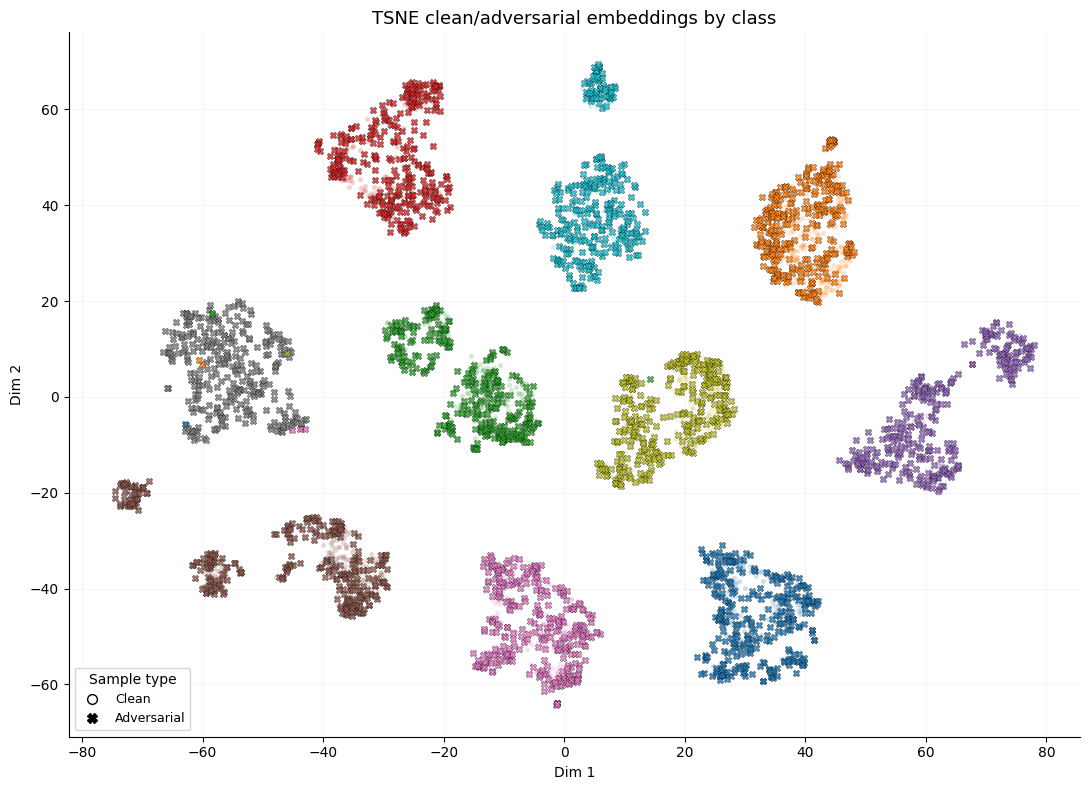

In [50]:
# =========================
# 9. Plot A: class clusters with clean/adversarial markers
#    Cleaner than the original plot: one legend for classes, one legend for marker type.
# =========================
def plot_class_clusters_readable(coords_clean, coords_adv, y, output_path: Path):
    fig, ax = plt.subplots(figsize=(11, 8))
    classes = sorted(np.unique(y).astype(int).tolist())

    # Clean points: faint circles
    for c in classes:
        m = y == c
        ax.scatter(
            coords_clean[m, 0], coords_clean[m, 1],
            s=13, alpha=0.22, marker="o",
            color=CLASS_COLORS.get(int(c), "black"),
            linewidths=0,
        )

    # Adversarial points: stronger X markers, same class color
    for c in classes:
        m = y == c
        ax.scatter(
            coords_adv[m, 0], coords_adv[m, 1],
            s=24, alpha=0.78, marker="X",
            color=CLASS_COLORS.get(int(c), "black"),
            linewidths=0.25,
            edgecolors="black",
        )

    setup_axis(ax, f"{METHOD.upper()} clean/adversarial embeddings by class")
    add_class_legend(ax, classes=classes, loc="upper left", bbox_to_anchor=(1.02, 1.0))
    add_marker_legend(ax, loc="lower left")
    save_fig(fig, output_path)


plot_class_clusters_readable(
    coords_clean, coords_adv, y_np,
    OUTPUT_DIR / f"{METHOD}_{SPLIT}_A_class_clusters_readable"
)



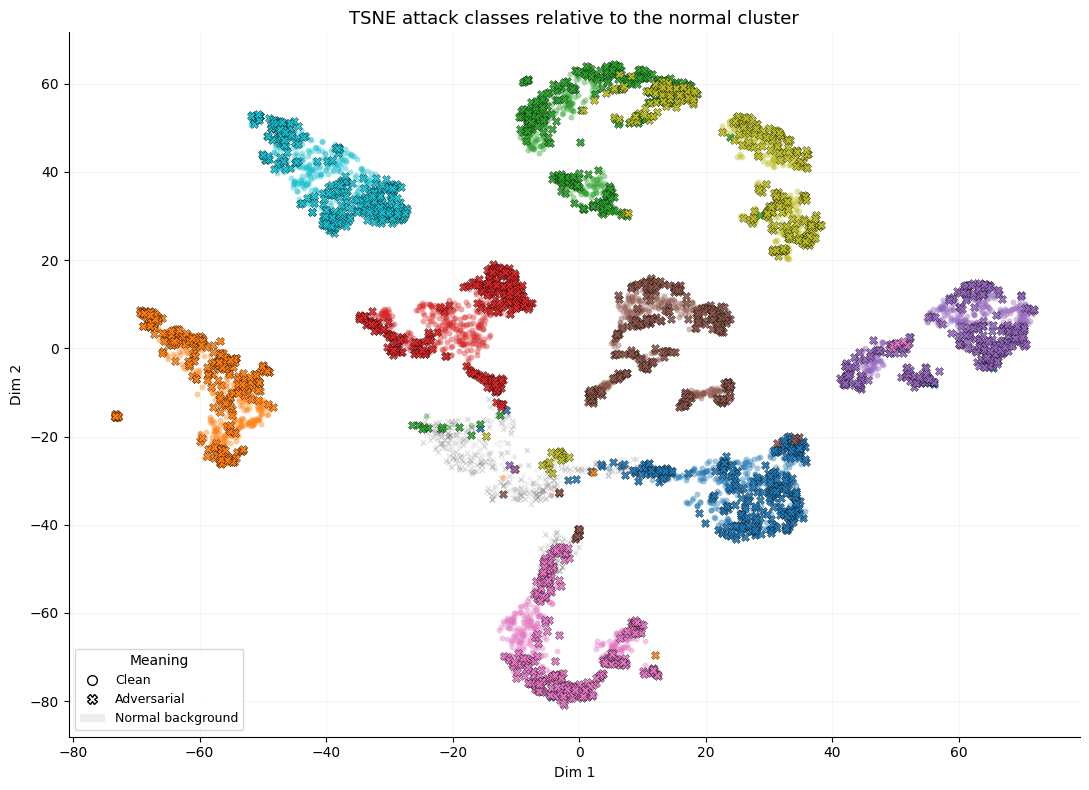

In [41]:
# =========================
# 10. Plot B: attack-vs-normal view
#     This is often the easiest figure for IDS papers.
#     Normal is shown as a light gray background; attacks are colored.
# =========================
def plot_attack_vs_normal(coords_clean, coords_adv, y, output_path: Path):
    fig, ax = plt.subplots(figsize=(11, 8))
    normal = y == 0
    attack = y != 0
    attack_classes = sorted(np.unique(y[attack]).astype(int).tolist())

    # Normal background
    ax.scatter(coords_clean[normal, 0], coords_clean[normal, 1],
               s=11, alpha=0.12, c="#9e9e9e", marker="o", linewidths=0,
               label="Normal clean background")
    ax.scatter(coords_adv[normal, 0], coords_adv[normal, 1],
               s=14, alpha=0.22, c="#4d4d4d", marker="x", linewidths=0.7,
               label="Normal adversarial background")

    # Attack classes
    for c in attack_classes:
        m = y == c
        color = CLASS_COLORS.get(int(c), "black")
        ax.scatter(coords_clean[m, 0], coords_clean[m, 1],
                   s=18, alpha=0.42, marker="o", color=color, linewidths=0)
        ax.scatter(coords_adv[m, 0], coords_adv[m, 1],
                   s=34, alpha=0.90, marker="X", color=color,
                   edgecolors="black", linewidths=0.25)

    setup_axis(ax, f"{METHOD.upper()} attack classes relative to the normal cluster")
    add_class_legend(ax, classes=attack_classes, title="Attack class", loc="upper left", bbox_to_anchor=(1.02, 1.0))

    marker_handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=7,
               markerfacecolor="white", markeredgecolor="black", label="Clean"),
        Line2D([0], [0], marker="X", linestyle="", markersize=7,
               markerfacecolor="white", markeredgecolor="black", label="Adversarial"),
        Patch(facecolor="#9e9e9e", alpha=0.18, label="Normal background"),
    ]
    ax.legend(handles=marker_handles, title="Meaning", loc="lower left", frameon=True,
              fontsize=9, title_fontsize=10)
    save_fig(fig, output_path)


plot_attack_vs_normal(
    coords_clean, coords_adv, y_np,
    OUTPUT_DIR / f"{METHOD}_{SPLIT}_B_attack_vs_normal"
)



In [ ]:
# =========================
# 11. Plot C: adversarial prediction status
#     This highlights where adversarial examples go wrong.
# =========================
def plot_adv_status_readable(coords_clean, coords_adv, y, pred_clean, pred_adv, output_path: Path):
    fig, ax = plt.subplots(figsize=(10.5, 8))

    normal = y == 0
    attack = y != 0
    adv_correct = pred_adv == y
    adv_f2b = attack & (pred_adv == 0)
    adv_wrong_other = (~adv_correct) & (~adv_f2b)

    # Put clean embeddings in the background to show the learned manifold.
    ax.scatter(coords_clean[normal, 0], coords_clean[normal, 1],
               s=10, alpha=0.10, c="#bdbdbd", marker="o", linewidths=0,
               label="Clean normal background")
    ax.scatter(coords_clean[attack, 0], coords_clean[attack, 1],
               s=10, alpha=0.13, c="#636363", marker="o", linewidths=0,
               label="Clean attack background")

    # Correct adversarial samples are shown lightly.
    ax.scatter(coords_adv[adv_correct, 0], coords_adv[adv_correct, 1],
               s=18, alpha=0.28, c="#2ca02c", marker="x", linewidths=0.75,
               label="Adv correct")

    # Security-critical failures are highlighted strongly.
    if adv_wrong_other.sum() > 0:
        ax.scatter(coords_adv[adv_wrong_other, 0], coords_adv[adv_wrong_other, 1],
                   s=46, alpha=0.88, c="#ff7f0e", marker="^",
                   edgecolors="black", linewidths=0.35,
                   label="Adv wrong other")
    if adv_f2b.sum() > 0:
        ax.scatter(coords_adv[adv_f2b, 0], coords_adv[adv_f2b, 1],
                   s=80, alpha=0.98, c="#d62728", marker="*",
                   edgecolors="black", linewidths=0.55,
                   label="Adv attack→normal")

    setup_axis(ax, f"{METHOD.upper()} adversarial error status")
    ax.legend(loc="best", frameon=True, fontsize=9)
    txt = f"Adv attack→normal: {int(adv_f2b.sum())}/{int(attack.sum())}\nAdv wrong other: {int(adv_wrong_other.sum())}/{len(y)}"
    ax.text(0.01, 0.01, txt, transform=ax.transAxes, fontsize=10,
            va="bottom", ha="left", bbox=dict(boxstyle="round", facecolor="white", alpha=0.82, linewidth=0.5))
    save_fig(fig, output_path)


plot_adv_status_readable(
    coords_clean, coords_adv, y_np, pred_clean, pred_adv,
    OUTPUT_DIR / f"{METHOD}_{SPLIT}_C_adv_status_readable"
)



In [ ]:
# =========================
# 12. Plot D: per-attack-class panels
#     This is the clearest way to see each attack class against normal.
# =========================
def plot_per_attack_panels(coords_clean, coords_adv, y, output_path: Path):
    attack_classes = [int(c) for c in sorted(np.unique(y).tolist()) if int(c) != 0]
    ncols = 3
    nrows = int(np.ceil(len(attack_classes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.2 * nrows), sharex=True, sharey=True)
    axes = np.array(axes).reshape(-1)

    normal = y == 0
    for ax, c in zip(axes, attack_classes):
        m = y == c
        color = CLASS_COLORS.get(c, "black")

        # Normal background, clean only, so every panel has the same reference.
        ax.scatter(coords_clean[normal, 0], coords_clean[normal, 1],
                   s=8, alpha=0.08, c="#9e9e9e", marker="o", linewidths=0)

        # The selected attack class.
        ax.scatter(coords_clean[m, 0], coords_clean[m, 1],
                   s=24, alpha=0.45, c=color, marker="o", linewidths=0,
                   label="Clean")
        ax.scatter(coords_adv[m, 0], coords_adv[m, 1],
                   s=42, alpha=0.92, c=color, marker="X",
                   edgecolors="black", linewidths=0.3,
                   label="Adversarial")

        ax.set_title(f"{cname(c)} vs normal", fontsize=12)
        ax.grid(True, alpha=0.15, linewidth=0.6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(loc="best", fontsize=8, frameon=True)

    for ax in axes[len(attack_classes):]:
        ax.axis("off")

    fig.suptitle(f"{METHOD.upper()} per-class clean/adversarial embeddings relative to normal", fontsize=15, y=1.01)
    fig.supxlabel("Dim 1")
    fig.supylabel("Dim 2")
    fig.tight_layout()
    fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(output_path.with_suffix(".pdf"), bbox_inches="tight")
    plt.show()


plot_per_attack_panels(
    coords_clean, coords_adv, y_np,
    OUTPUT_DIR / f"{METHOD}_{SPLIT}_D_per_attack_panels"
)



In [ ]:
# =========================
# 13. Plot E: clean-to-adversarial shift, attack samples only
#     Draw fewer arrows to avoid clutter.
# =========================
def plot_attack_shift_only(coords_clean, coords_adv, y, pred_adv, output_path: Path, max_pairs_per_class: int = 45):
    rng = np.random.default_rng(SEED)
    attack_classes = [int(c) for c in sorted(np.unique(y).tolist()) if int(c) != 0]
    selected = []
    for c in attack_classes:
        ids = np.where(y == c)[0]
        if len(ids) > max_pairs_per_class:
            ids = rng.choice(ids, size=max_pairs_per_class, replace=False)
        selected.extend(ids.tolist())
    selected = np.array(selected, dtype=int)

    fig, ax = plt.subplots(figsize=(10.5, 8))
    # normal reference
    normal = y == 0
    ax.scatter(coords_clean[normal, 0], coords_clean[normal, 1],
               s=8, alpha=0.08, c="#9e9e9e", marker="o", linewidths=0,
               label="Normal clean background")

    for i in selected:
        c = int(y[i])
        color = CLASS_COLORS.get(c, "black")
        is_f2b = (pred_adv[i] == 0)
        ax.plot([coords_clean[i, 0], coords_adv[i, 0]],
                [coords_clean[i, 1], coords_adv[i, 1]],
                color="#d62728" if is_f2b else color,
                linewidth=1.0 if is_f2b else 0.55,
                alpha=0.85 if is_f2b else 0.32)

    ax.scatter(coords_clean[selected, 0], coords_clean[selected, 1],
               s=22, alpha=0.50, c=[CLASS_COLORS.get(int(y[i]), "black") for i in selected],
               marker="o", linewidths=0, label="Attack clean")
    ax.scatter(coords_adv[selected, 0], coords_adv[selected, 1],
               s=38, alpha=0.90, c=[CLASS_COLORS.get(int(y[i]), "black") for i in selected],
               marker="X", edgecolors="black", linewidths=0.25, label="Attack adversarial")

    # explicitly mark attack -> normal cases among the selected arrows
    f2b_selected = selected[pred_adv[selected] == 0]
    if len(f2b_selected) > 0:
        ax.scatter(coords_adv[f2b_selected, 0], coords_adv[f2b_selected, 1],
                   s=95, c="#d62728", marker="*", edgecolors="black", linewidths=0.5,
                   label="Attack→normal")

    setup_axis(ax, f"{METHOD.upper()} attack clean-to-adversarial shifts")
    ax.legend(loc="best", frameon=True, fontsize=9)
    save_fig(fig, output_path)


plot_attack_shift_only(
    coords_clean, coords_adv, y_np, pred_adv,
    OUTPUT_DIR / f"{METHOD}_{SPLIT}_E_attack_shift_only"
)



In [ ]:
# =========================
# 14. Quantitative summary and save arrays
# =========================
clean_acc = float(accuracy_score(y_np, pred_clean))
adv_acc = float(accuracy_score(y_np, pred_adv))
clean_macro_f1 = float(f1_score(y_np, pred_clean, average="macro", zero_division=0))
adv_macro_f1 = float(f1_score(y_np, pred_adv, average="macro", zero_division=0))
attack_mask = y_np != 0
adv_f2b = float(np.mean(pred_adv[attack_mask] == 0)) if attack_mask.sum() > 0 else 0.0
avg_shift_2d = float(np.mean(np.linalg.norm(coords_adv - coords_clean, axis=1)))
avg_shift_feat = float(np.mean(np.linalg.norm(z_adv - z_clean, axis=1)))

summary = {
    "split": SPLIT,
    "num_selected": int(len(y_np)),
    "method": METHOD,
    "attack": ATTACK,
    "epsilon": float(eps),
    "attack_alpha": float(alpha),
    "attack_steps": int(ATTACK_STEPS),
    "clean_acc_on_selected": clean_acc,
    "adv_acc_on_selected": adv_acc,
    "clean_macro_f1_on_selected": clean_macro_f1,
    "adv_macro_f1_on_selected": adv_macro_f1,
    "adv_fool_to_benign_on_selected": adv_f2b,
    "avg_clean_to_adv_shift_2d": avg_shift_2d,
    "avg_clean_to_adv_shift_feature": avg_shift_feat,
    "class_names": class_names,
}

print(json.dumps(summary, indent=2))

with open(OUTPUT_DIR / "tsne_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

np.savez_compressed(
    OUTPUT_DIR / "clean_adv_projection.npz",
    coords_clean=coords_clean,
    coords_adv=coords_adv,
    z_clean=z_clean,
    z_adv=z_adv,
    y=y_np,
    pred_clean=pred_clean,
    pred_adv=pred_adv,
    selected_indices=idx.numpy(),
    class_names=np.array(class_names, dtype=object),
)

print("Saved figures and arrays to:", OUTPUT_DIR)


## Cách đọc các hình mới

- **Plot A**: xem tổng quan tất cả class. Màu là class, `o` là clean, `X` là adversarial. Legend đã tách riêng class và marker để tránh bị rối.
- **Plot B**: xem các attack class so với normal. Normal được làm nền xám mờ; mỗi attack có clean/adversarial riêng. Đây là hình nên dùng trong paper nếu muốn nhấn mạnh attack-vs-normal boundary.
- **Plot C**: xem lỗi adversarial. Điểm `Adv attack→normal` được đánh dấu sao đỏ vì đây là lỗi nguy hiểm nhất trong IDS.
- **Plot D**: từng attack class so với normal trong các panel riêng. Đây là hình dễ đọc nhất khi muốn phân tích class nào bị gần normal.
- **Plot E**: hướng dịch chuyển từ clean sang adversarial cho attack samples. Đường dài hoặc hướng về normal cho thấy perturbation đang đẩy embedding đến vùng nguy hiểm.


## 15. Clearer attack-focused visualizations
The plots below are designed to make **clean attack** vs **adversarial attack** much easier to distinguish.

Design choices:
- **Normal** samples are shown only as a faint gray background.
- **Clean attack** samples are drawn as **large hollow circles** with colored edges.
- **Adversarial attack** samples are drawn as **filled X markers** in the same class color.
- Class centroids for clean and adversarial samples are shown and connected by an arrow.
- Additional attack-only plots remove normal entirely so overlap is easier to inspect.


In [ ]:

# =========================
# 15. Clearer attack-focused plot helpers
# =========================
from matplotlib.lines import Line2D

ATTACK_FOCUS_DIR = OUTPUT_DIR / "attack_focus"
ATTACK_FOCUS_DIR.mkdir(parents=True, exist_ok=True)


def _class_name(c: int) -> str:
    return class_names[c] if c < len(class_names) else f"class_{c}"


def plot_attack_only_overlay(coords_clean, coords_adv, y, output_path: Path):
    """Show only attack classes: clean=hollow circles, adv=filled X."""
    fig, ax = plt.subplots(figsize=(11.5, 8.5))
    attack_classes = [int(c) for c in sorted(np.unique(y).tolist()) if int(c) != 0]

    for c in attack_classes:
        m = y == c
        col = CLASS_COLORS.get(c, None)
        # Clean attack: hollow circles
        ax.scatter(
            coords_clean[m, 0], coords_clean[m, 1],
            s=42, marker='o', facecolors='none', edgecolors=col,
            linewidths=1.3, alpha=0.95, label=f"{_class_name(c)} clean"
        )
        # Adv attack: filled X
        ax.scatter(
            coords_adv[m, 0], coords_adv[m, 1],
            s=34, marker='X', c=col, edgecolors='k', linewidths=0.35,
            alpha=0.92, label=f"{_class_name(c)} adv"
        )

        # centroids + shift arrow
        cc = coords_clean[m].mean(axis=0)
        ca = coords_adv[m].mean(axis=0)
        ax.scatter([cc[0]], [cc[1]], s=130, marker='o', facecolors='white', edgecolors='black', linewidths=1.2, zorder=6)
        ax.scatter([ca[0]], [ca[1]], s=140, marker='X', c=col, edgecolors='black', linewidths=0.8, zorder=7)
        ax.annotate('', xy=(ca[0], ca[1]), xytext=(cc[0], cc[1]),
                    arrowprops=dict(arrowstyle='->', lw=1.2, color=col, alpha=0.85), zorder=5)

    ax.set_title("t-SNE: CE baseline attack classes only (clean vs adversarial)")
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")
    ax.grid(True, alpha=0.18)

    # two legends: marker meaning + class colors
    marker_handles = [
        Line2D([0], [0], marker='o', color='black', label='Clean attack', markersize=8, linestyle='None', markerfacecolor='white'),
        Line2D([0], [0], marker='X', color='black', label='Adversarial attack', markersize=8, linestyle='None')
    ]
    leg1 = ax.legend(handles=marker_handles, loc='upper left', frameon=True, title='Sample type')
    ax.add_artist(leg1)

    class_handles = [
        Line2D([0], [0], marker='s', color='w', label=_class_name(c), markerfacecolor=CLASS_COLORS.get(c), markersize=8)
        for c in attack_classes
    ]
    ax.legend(handles=class_handles, loc='lower left', ncol=2, frameon=True, title='Attack class')

    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_attack_class_panels_strict(coords_clean, coords_adv, y, output_path: Path):
    """One panel per attack class with normal as faint background."""
    attack_classes = [int(c) for c in sorted(np.unique(y).tolist()) if int(c) != 0]
    ncols = 3
    nrows = int(np.ceil(len(attack_classes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15.5, 4.4 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    normal = (y == 0)
    xlim = (min(coords_clean[:,0].min(), coords_adv[:,0].min()) - 3, max(coords_clean[:,0].max(), coords_adv[:,0].max()) + 3)
    ylim = (min(coords_clean[:,1].min(), coords_adv[:,1].min()) - 3, max(coords_clean[:,1].max(), coords_adv[:,1].max()) + 3)

    for ax, c in zip(axes, attack_classes):
        col = CLASS_COLORS.get(c)
        m = (y == c)
        # normal background
        ax.scatter(coords_clean[normal, 0], coords_clean[normal, 1], s=10, c='#bcbcbc', alpha=0.18, linewidths=0)
        # clean attack
        ax.scatter(coords_clean[m, 0], coords_clean[m, 1], s=44, marker='o', facecolors='none', edgecolors=col, linewidths=1.25, alpha=0.95)
        # adv attack
        ax.scatter(coords_adv[m, 0], coords_adv[m, 1], s=38, marker='X', c=col, edgecolors='k', linewidths=0.35, alpha=0.94)

        cc = coords_clean[m].mean(axis=0)
        ca = coords_adv[m].mean(axis=0)
        ax.scatter([cc[0]], [cc[1]], s=130, marker='o', facecolors='white', edgecolors=col, linewidths=1.8, zorder=6)
        ax.scatter([ca[0]], [ca[1]], s=130, marker='X', c=col, edgecolors='black', linewidths=0.8, zorder=7)
        ax.annotate('', xy=(ca[0], ca[1]), xytext=(cc[0], cc[1]),
                    arrowprops=dict(arrowstyle='->', lw=1.25, color=col, alpha=0.95), zorder=5)

        ax.set_title(f"{_class_name(c)}")
        ax.grid(True, alpha=0.16)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)

    for ax in axes[len(attack_classes):]:
        ax.axis('off')

    handles = [
        Line2D([0], [0], marker='o', color='black', label='Clean attack', markersize=8, linestyle='None', markerfacecolor='white'),
        Line2D([0], [0], marker='X', color='black', label='Adversarial attack', markersize=8, linestyle='None'),
        Line2D([0], [0], marker='o', color='#bcbcbc', label='Normal background', markersize=6, linestyle='None')
    ]
    fig.legend(handles=handles, loc='upper center', ncol=3, frameon=True, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle("CE baseline per-attack-class view: clean vs adversarial attacks", y=1.06, fontsize=14)
    fig.supxlabel("Dim 1")
    fig.supylabel("Dim 2")
    fig.tight_layout()
    fig.savefig(output_path, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_focus_class_with_pairs(coords_clean, coords_adv, y, pred_adv, class_id: int, output_path: Path, max_pairs: int = 70):
    """Detailed view for one chosen class, with a subset of clean->adv pair lines."""
    fig, ax = plt.subplots(figsize=(9.5, 8.2))
    normal = y == 0
    m = y == class_id
    col = CLASS_COLORS.get(class_id)

    # normal as faint background
    ax.scatter(coords_clean[normal, 0], coords_clean[normal, 1], s=11, c='#c8c8c8', alpha=0.16, linewidths=0, label='Normal clean')
    # clean focus class
    ax.scatter(coords_clean[m, 0], coords_clean[m, 1], s=50, marker='o', facecolors='none', edgecolors=col, linewidths=1.35, alpha=0.98, label=f'{_class_name(class_id)} clean')
    # adv focus class
    ax.scatter(coords_adv[m, 0], coords_adv[m, 1], s=45, marker='X', c=col, edgecolors='k', linewidths=0.4, alpha=0.95, label=f'{_class_name(class_id)} adv')

    # subset of pair lines
    ids = np.where(m)[0]
    rng = np.random.default_rng(SEED + int(class_id))
    if len(ids) > max_pairs:
        ids = rng.choice(ids, size=max_pairs, replace=False)
    for i in ids:
        x1, y1 = coords_clean[i]
        x2, y2 = coords_adv[i]
        ax.plot([x1, x2], [y1, y2], color=col, alpha=0.22, lw=0.9)

    # highlight attack->normal failures
    adv_f2b = m & (pred_adv == 0)
    if adv_f2b.any():
        ax.scatter(coords_adv[adv_f2b, 0], coords_adv[adv_f2b, 1], s=100, marker='*', c='red', edgecolors='black', linewidths=0.6, alpha=0.95, label='Adv attack→normal')

    cc = coords_clean[m].mean(axis=0)
    ca = coords_adv[m].mean(axis=0)
    ax.scatter([cc[0]], [cc[1]], s=140, marker='o', facecolors='white', edgecolors=col, linewidths=2.0, zorder=6)
    ax.scatter([ca[0]], [ca[1]], s=150, marker='X', c=col, edgecolors='black', linewidths=0.8, zorder=7)
    ax.annotate('', xy=(ca[0], ca[1]), xytext=(cc[0], cc[1]), arrowprops=dict(arrowstyle='->', lw=1.4, color=col), zorder=6)

    ax.set_title(f"CE baseline focused view: {_class_name(class_id)} clean vs adversarial")
    ax.set_xlabel('Dim 1')
    ax.set_ylabel('Dim 2')
    ax.grid(True, alpha=0.18)
    ax.legend(loc='best', frameon=True)
    fig.tight_layout()
    fig.savefig(output_path, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)




In [ ]:

# =========================
# 16. Generate clearer attack-focused plots
# =========================
plot_attack_only_overlay(coords_clean, coords_adv, y_np, ATTACK_FOCUS_DIR / f"{SPLIT}_{ATTACK}_{METHOD}_attack_only_overlay.png")

plot_attack_class_panels_strict(coords_clean, coords_adv, y_np, ATTACK_FOCUS_DIR / f"{SPLIT}_{ATTACK}_{METHOD}_attack_panels_strict.png")

# Choose a focus attack class here (change if desired)
FOCUS_CLASS_ID = 9 if 9 in np.unique(y_np) else int(sorted([c for c in np.unique(y_np) if c != 0])[0])
plot_focus_class_with_pairs(
    coords_clean, coords_adv, y_np, pred_adv,
    class_id=FOCUS_CLASS_ID,
    output_path=ATTACK_FOCUS_DIR / f"{SPLIT}_{ATTACK}_{METHOD}_focus_class_{FOCUS_CLASS_ID}.png",
    max_pairs=70,
)

print("Saved clearer attack-focused plots to:", ATTACK_FOCUS_DIR)


